# 02 - Feature Engineering: from raw sensors to predictive signal

Two families of features: **physics/domain features** (tabular) and **rolling-window features** (time series).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import load_ai4i, load_stream
from src.preprocessing import clean_ai4i, clean_stream
from src.feature_engineering import (build_ai4i_features, build_stream_features,
                                     stream_feature_columns)
from src import config
sns.set_theme(style='whitegrid')
%matplotlib inline

## 2.1 Physics features (AI4I)
`mechanical_power = torque x angular velocity`, `temp_difference = process - air`, `tool_wear_rate`, `wear x torque` interaction, `rpm_deviation` from the healthy band.

In [2]:
df = build_ai4i_features(clean_ai4i(load_ai4i()))
df[['torque_nm','rotational_speed_rpm','mechanical_power_w',
    'temp_difference_k','tool_wear_rate','wear_x_torque','machine_failure']].head()

12:49:51 | INFO    | clean_ai4i: 10000 -> 10000 rows, 15 cols


12:49:51 | INFO    | build_ai4i_features: 9 engineered features added


,torque_nm,rotational_speed_rpm,mechanical_power_w,temp_difference_k,tool_wear_rate,wear_x_torque,machine_failure
0,42.8,1551,6951.590560,10.5,0.000000,0.0,0
1,46.3,1408,6826.722724,10.5,0.439449,138.9,0
2,49.4,1498,7749.387543,10.4,0.645212,247.0,0
3,39.5,1433,5927.504659,10.4,1.180935,276.5,0
4,40.0,1408,5897.816608,10.5,1.525988,360.0,0


### Do the engineered features separate failures better than raw sensors?

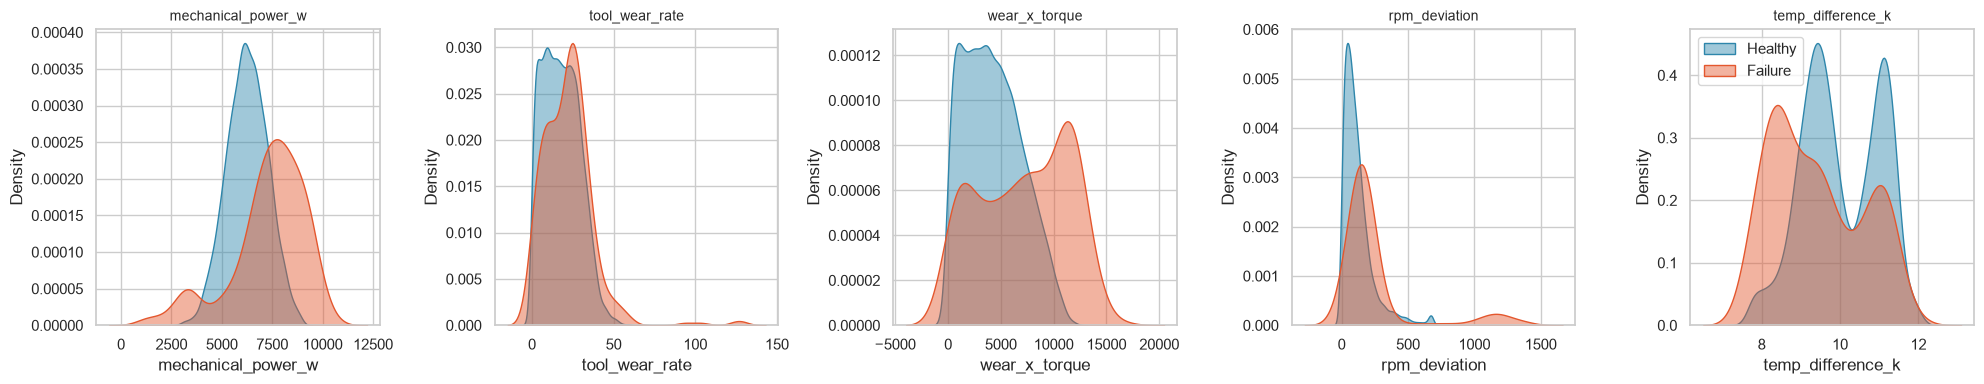

In [3]:
eng = ['mechanical_power_w','tool_wear_rate','wear_x_torque','rpm_deviation','temp_difference_k']
fig, axes = plt.subplots(1, len(eng), figsize=(20, 4))
for ax, col in zip(axes, eng):
    for lab, c in [(0, '#2E86AB'), (1, '#E4572E')]:
        sns.kdeplot(df.loc[df.machine_failure == lab, col], ax=ax, fill=True, alpha=.45,
                    color=c, label='Failure' if lab else 'Healthy', warn_singular=False)
    ax.set_title(col, fontsize=10)
axes[-1].legend()
plt.tight_layout()

## 2.2 Time-series window features (virtual IoT fleet)
A single vibration reading is ambiguous; a *rising* vibration with growing variance is a failing bearing. For each sensor we compute rolling mean / std / min / max / range / trend over 5- and 15-cycle windows, plus deltas and per-machine baseline z-scores.

In [4]:
stream = clean_stream(load_stream())
feat = build_stream_features(stream)
cols = stream_feature_columns(feat)
print('model input features:', len(cols))
feat[cols[:12]].head(3)

12:49:55 | INFO    | clean_stream: 27000 -> 27000 rows


12:49:56 | INFO    | build_stream_features: table is now 119 columns


model input features: 92


,acoustic_db,acoustic_db_delta_1,acoustic_db_max_15,acoustic_db_max_5,acoustic_db_mean_15,acoustic_db_mean_5,acoustic_db_min_15,acoustic_db_min_5,acoustic_db_range_15,acoustic_db_range_5,acoustic_db_std_15,acoustic_db_std_5
0,76.15,NaN,76.15,76.15,76.150,76.150,76.15,76.15,0.00,0.00,NaN,NaN
1,76.30,0.15,76.30,76.30,76.225,76.225,76.15,76.15,0.15,0.15,0.106066,0.106066
2,75.73,-0.57,76.30,76.30,76.060,76.060,75.73,75.73,0.57,0.57,0.295466,0.295466


### Visual proof: the same sensor, before vs during degradation

Text(0.5, 0.98, 'Window features expose degradation that raw samples hide')

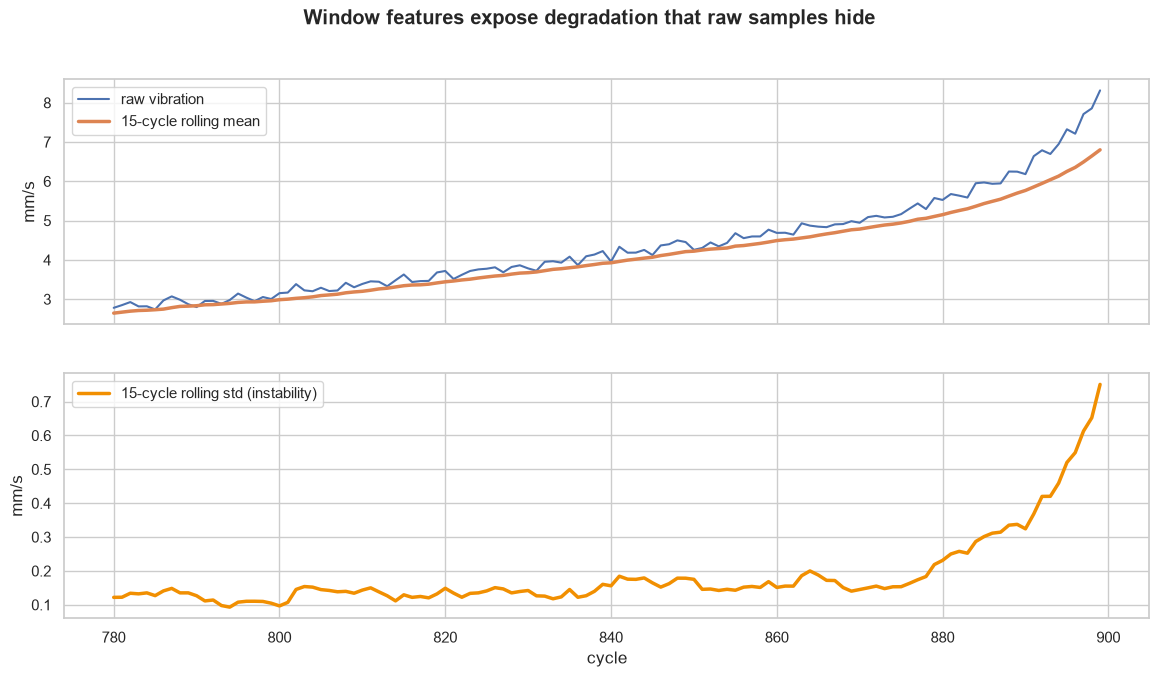

In [5]:
mid = 'MOTOR-001'
d = feat[feat.machine_id == mid].tail(120)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(d.cycle, d.vibration_mm_s, label='raw vibration')
axes[0].plot(d.cycle, d.vibration_mm_s_mean_15, lw=2.5, label='15-cycle rolling mean')
axes[0].legend(); axes[0].set_ylabel('mm/s')
axes[1].plot(d.cycle, d.vibration_mm_s_std_15, color='#F18F01', lw=2.5,
             label='15-cycle rolling std (instability)')
axes[1].legend(); axes[1].set_ylabel('mm/s'); axes[1].set_xlabel('cycle')
plt.suptitle('Window features expose degradation that raw samples hide', fontweight='bold')

## 2.3 Leakage guard
`stream_feature_columns()` deliberately excludes `failure_now`, `failure_within_horizon`, `health_index`, `fault_mode` and the per-machine `*_baseline` constants. Any of those in the feature set would give a fake 100% score - the classic beginner mistake that makes a project worthless.

In [6]:
banned = ['failure_now', config.STREAM_TARGET, 'health_index', 'fault_mode']
print('leak check ->', {b: (b in cols) for b in banned})
print('baseline columns excluded:', [c for c in feat.columns if c.endswith('_baseline')][:5])

leak check -> {'failure_now': False, 'failure_within_horizon': False, 'health_index': False, 'fault_mode': False}
baseline columns excluded: ['temperature_c_baseline', 'vibration_mm_s_baseline', 'current_a_baseline', 'pressure_bar_baseline', 'rpm_baseline']
